## 1. Spark и библиотеки

In [1]:
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, TrainValidationSplit
from pyspark.ml.functions import vector_to_array

spark = (SparkSession.builder.master("local[6]").appName("credit-card-fraud")
         .config("spark.sql.shuffle.partitions", "12").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

## 2. Данные и качество

In [2]:
raw = spark.read.csv("data/creditcard.csv", header=True, inferSchema=True).cache()
raw.printSchema()
raw.select("Time", "Amount", "V1", "V2", "Class").show(5)
print("строк:", raw.count(), "полных повторов:", raw.count() - raw.dropDuplicates().count())
display(raw.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in raw.columns]).toPandas())
data = raw.dropDuplicates().withColumnRenamed("Class", "label").cache()
display(data.groupBy("label").count().orderBy("label").toPandas())

root
 |-- Time: double (nullable = true)
 |-- V1: double (nullable = true)
 |-- V2: double (nullable = true)
 |-- V3: double (nullable = true)
 |-- V4: double (nullable = true)
 |-- V5: double (nullable = true)
 |-- V6: double (nullable = true)
 |-- V7: double (nullable = true)
 |-- V8: double (nullable = true)
 |-- V9: double (nullable = true)
 |-- V10: double (nullable = true)
 |-- V11: double (nullable = true)
 |-- V12: double (nullable = true)
 |-- V13: double (nullable = true)
 |-- V14: double (nullable = true)
 |-- V15: double (nullable = true)
 |-- V16: double (nullable = true)
 |-- V17: double (nullable = true)
 |-- V18: double (nullable = true)
 |-- V19: double (nullable = true)
 |-- V20: double (nullable = true)
 |-- V21: double (nullable = true)
 |-- V22: double (nullable = true)
 |-- V23: double (nullable = true)
 |-- V24: double (nullable = true)
 |-- V25: double (nullable = true)
 |-- V26: double (nullable = true)
 |-- V27: double (nullable = true)
 |-- V28: double (nulla

+----+------+------------------+-------------------+-----+
|Time|Amount|                V1|                 V2|Class|
+----+------+------------------+-------------------+-----+
| 0.0|149.62|  -1.3598071336738|-0.0727811733098497|    0|
| 0.0|  2.69|  1.19185711131486|   0.26615071205963|    0|
| 1.0|378.66| -1.35835406159823|  -1.34016307473609|    0|
| 1.0| 123.5|-0.966271711572087| -0.185226008082898|    0|
| 2.0| 69.99| -1.15823309349523|  0.877736754848451|    0|
+----+------+------------------+-------------------+-----+
only showing top 5 rows



строк: 284807 полных повторов: 1081


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


,label,count
0,0,283253
1,1,473


## 3. Разведочный анализ

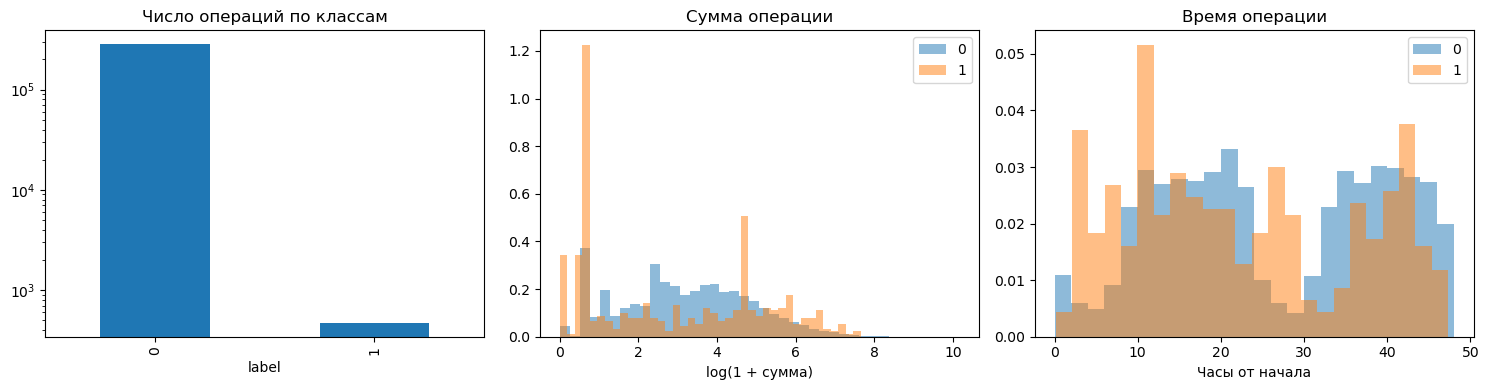

,label,mean_amount,max_amount
0,0,88.413575,25691.16
1,1,123.871860,2125.87


In [3]:
eda = data.select("Time", "Amount", "label").toPandas()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
eda.label.value_counts().sort_index().plot.bar(ax=axes[0], logy=True, title="Число операций по классам")
for label, group in eda.groupby("label"):
    axes[1].hist(np.log1p(group.Amount), bins=40, density=True, alpha=.5, label=str(label))
    axes[2].hist(group.Time / 3600, bins=24, density=True, alpha=.5, label=str(label))
axes[1].set(xlabel="log(1 + сумма)", title="Сумма операции")
axes[2].set(xlabel="Часы от начала", title="Время операции")
axes[1].legend(); axes[2].legend()
plt.tight_layout()
plt.show()
display(data.groupBy("label").agg(F.avg("Amount").alias("mean_amount"), F.max("Amount").alias("max_amount")).toPandas())

## 4. Обучающая, валидационная и тестовая выборки

In [4]:
t1, t2 = data.approxQuantile("Time", [.6, .8], .001)
train = data.filter(F.col("Time") <= t1).cache()
valid = data.filter((F.col("Time") > t1) & (F.col("Time") <= t2)).cache()
test = data.filter(F.col("Time") > t2).cache()
display(pd.DataFrame([(name, frame.count(), frame.filter("label = 1").count())
                      for name, frame in [("train", train), ("validation", valid), ("test", test)]],
                     columns=["split", "rows", "fraud"]))
features = [f"V{i}" for i in range(1, 29)] + ["Amount"]
assembler = VectorAssembler(inputCols=features, outputCol="raw_features")
scaler = StandardScaler(inputCol="raw_features", outputCol="features", withMean=True, withStd=True)

,split,rows,fraud
0,train,170037,342
1,validation,56738,57
2,test,56951,74


## 5. Метрики классификации

In [5]:
pr = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderPR", numBins=0)

def evaluate(model, frame, name):
    predictions = model.transform(frame).cache()
    counts = {(int(r.label), int(r.prediction)): r["count"]
              for r in predictions.groupBy("label", "prediction").count().collect()}
    tp, fp, fn = counts.get((1, 1), 0), counts.get((0, 1), 0), counts.get((1, 0), 0)
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    result = dict(model=name, pr_auc=pr.evaluate(predictions), precision=precision, recall=recall,
                  f1=2 * precision * recall / max(precision + recall, 1e-15), tp=tp, fp=fp, fn=fn, tn=counts.get((0, 0), 0))
    predictions.unpersist()
    return result

## 6. Базовая логистическая регрессия

In [6]:
lr = LogisticRegression(maxIter=100, regParam=.01, standardization=False)
lr_pipeline = Pipeline(stages=[assembler, scaler, lr])
lr_model = lr_pipeline.fit(train)
lr_result = evaluate(lr_model, valid, "logistic regression")
display(pd.DataFrame([lr_result]))

,model,pr_auc,precision,recall,f1,tp,fp,fn,tn
0,logistic regression,0.773717,1.0,0.017544,0.034483,1,0,56,56681


## 7. Логистическая регрессия с весами классов

In [7]:
weighted_train = train.withColumn("weight", F.when(F.col("label") == 1, 10.0).otherwise(1.0))
weighted_lr = LogisticRegression(maxIter=100, regParam=.01, standardization=False, weightCol="weight")
weighted_model = Pipeline(stages=[assembler, scaler, weighted_lr]).fit(weighted_train)
weighted_result = evaluate(weighted_model, valid, "weighted logistic regression")
display(pd.DataFrame([lr_result, weighted_result]))

,model,pr_auc,precision,recall,f1,tp,fp,fn,tn
0,logistic regression,0.773717,1.000000,0.017544,0.034483,1,0,56,56681
1,weighted logistic regression,0.752454,0.721311,0.771930,0.745763,44,17,13,56664


## 8. Случайный лес

In [8]:
rf = RandomForestClassifier(featuresCol="raw_features", numTrees=50, maxDepth=5, seed=42)
rf_pipeline = Pipeline(stages=[assembler, rf])
rf_model = rf_pipeline.fit(train)
rf_result = evaluate(rf_model, valid, "random forest")
display(pd.DataFrame([lr_result, weighted_result, rf_result]))

,model,pr_auc,precision,recall,f1,tp,fp,fn,tn
0,logistic regression,0.773717,1.000000,0.017544,0.034483,1,0,56,56681
1,weighted logistic regression,0.752454,0.721311,0.771930,0.745763,44,17,13,56664
2,random forest,0.747523,0.948718,0.649123,0.770833,37,2,20,56679


## 9. Подбор параметров случайного леса

In [9]:
grid = ParamGridBuilder().addGrid(rf.numTrees, [50, 100]).addGrid(rf.maxDepth, [5, 10]).build()
search = TrainValidationSplit(estimator=rf_pipeline, estimatorParamMaps=grid, evaluator=pr,
                              trainRatio=.8, seed=42, parallelism=1)
search_model = search.fit(train)
tuned_model = search_model.bestModel
tuned_result = evaluate(tuned_model, valid, "tuned random forest")
display(pd.DataFrame([dict(numTrees=p[rf.numTrees], maxDepth=p[rf.maxDepth], inner_pr_auc=score)
                      for p, score in zip(grid, search_model.validationMetrics)]))
display(pd.DataFrame([lr_result, weighted_result, rf_result, tuned_result]))

,numTrees,maxDepth,inner_pr_auc
0,50,5,0.826196
1,50,10,0.874437
2,100,5,0.821705
3,100,10,0.863924


,model,pr_auc,precision,recall,f1,tp,fp,fn,tn
0,logistic regression,0.773717,1.000000,0.017544,0.034483,1,0,56,56681
1,weighted logistic regression,0.752454,0.721311,0.771930,0.745763,44,17,13,56664
2,random forest,0.747523,0.948718,0.649123,0.770833,37,2,20,56679
3,tuned random forest,0.756351,0.928571,0.684211,0.787879,39,3,18,56678


## 10. Выбор модели и итоговая тестовая оценка

In [10]:
models = [(lr_model, lr_result), (weighted_model, weighted_result), (rf_model, rf_result), (tuned_model, tuned_result)]
best_model, best_valid = max(models, key=lambda pair: pair[1]["pr_auc"])
test_result = evaluate(best_model, test, best_valid["model"])
display(pd.DataFrame([test_result]))
display(pd.DataFrame([[test_result["tn"], test_result["fp"]], [test_result["fn"], test_result["tp"]]],
                     index=["реально 0", "реально 1"], columns=["предсказано 0", "предсказано 1"]))

,model,pr_auc,precision,recall,f1,tp,fp,fn,tn
0,logistic regression,0.79472,1.0,0.202703,0.337079,15,0,59,56877


,предсказано 0,предсказано 1
реально 0,56877,0
реально 1,59,15


## 11. Spark на небольшой общей выборке

In [11]:
small_train = train.sampleBy("label", fractions={0: .35, 1: .35}, seed=42).cache()
print("строк для сравнения:", small_train.count())
small_pandas = small_train.select(*features, "label").toPandas()
test_pandas = test.select(*features, "label").toPandas()
comparison_lr = LogisticRegression(maxIter=300, tol=1e-6, regParam=0, standardization=False)
start = perf_counter()
small_spark_model = Pipeline(stages=[assembler, scaler, comparison_lr]).fit(small_train)
spark_seconds = perf_counter() - start
spark_comparison = evaluate(small_spark_model, test, "Spark LR")
spark_comparison["fit_seconds"] = spark_seconds
display(pd.DataFrame([spark_comparison]))

строк для сравнения: 59454


,model,pr_auc,precision,recall,f1,tp,fp,fn,tn,fit_seconds
0,Spark LR,0.637657,0.716981,0.513514,0.598425,38,15,36,56862,6.161083


## 12. Та же задача в sklearn

In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler as SklearnScaler
from sklearn.linear_model import LogisticRegression as SklearnLR
from sklearn.metrics import average_precision_score, precision_score, recall_score, f1_score

sklearn_model = make_pipeline(SklearnScaler(), SklearnLR(penalty=None, max_iter=300, tol=1e-6))
start = perf_counter()
sklearn_model.fit(small_pandas[features], small_pandas.label)
sklearn_seconds = perf_counter() - start
sklearn_probability = sklearn_model.predict_proba(test_pandas[features])[:, 1]
sklearn_prediction = sklearn_model.predict(test_pandas[features])
spark_scores = small_spark_model.transform(test).select("label", vector_to_array("probability")[1].alias("score")).toPandas()
display(pd.DataFrame([
    dict(library="Spark", ap=average_precision_score(spark_scores.label, spark_scores.score),
         precision=spark_comparison["precision"], recall=spark_comparison["recall"], f1=spark_comparison["f1"], seconds=spark_seconds),
    dict(library="sklearn", ap=average_precision_score(test_pandas.label, sklearn_probability),
         precision=precision_score(test_pandas.label, sklearn_prediction, zero_division=0),
         recall=recall_score(test_pandas.label, sklearn_prediction), f1=f1_score(test_pandas.label, sklearn_prediction), seconds=sklearn_seconds)
]))

,library,ap,precision,recall,f1,seconds
0,Spark,0.639130,0.716981,0.513514,0.598425,6.161083
1,sklearn,0.638897,0.716981,0.513514,0.598425,0.690810


## 13. Сохранение и повторная загрузка Pipeline

In [13]:
model_path = str(Path("models/fraud_pipeline").resolve())
best_model.write().overwrite().save(model_path)
loaded_model = PipelineModel.load(model_path)
sample = test.orderBy("Time", "Amount", "V1").limit(100).cache()
before = best_model.transform(sample).select(*features, "Time", "prediction", vector_to_array("probability").alias("probability"))
after = loaded_model.transform(sample).select(*features, "Time", "prediction", vector_to_array("probability").alias("probability"))
print("различий после загрузки:", before.exceptAll(after).count() + after.exceptAll(before).count())
after.select("Time", "Amount", "prediction", "probability").show(5, truncate=False)

различий после загрузки: 0


+--------+------+----------+-------------------------------------------+
|Time    |Amount|prediction|probability                                |
+--------+------+----------+-------------------------------------------+
|145145.0|4.49  |0.0       |[0.9988801260123686, 0.001119873987631359] |
|145145.0|4.49  |0.0       |[0.9987720423788731, 0.0012279576211269294]|
|145145.0|10.0  |0.0       |[0.9991278201389656, 8.721798610343834E-4] |
|145145.0|16.47 |0.0       |[0.9991265223106025, 8.734776893974949E-4] |
|145145.0|17.24 |0.0       |[0.9991746041012607, 8.253958987393117E-4] |
+--------+------+----------+-------------------------------------------+
only showing top 5 rows



## 14. Завершение

In [14]:
spark.stop()